Imports and paths

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
raw_data_dir = ROOT / "data" / "raw"
processed_data_dir = ROOT / "data" / "processed"
reports_figures = ROOT / "reports" / "figures"

Loading the data

In [3]:
pl_players_2025_26 = pd.read_csv(processed_data_dir / "pl_players_2025_26.csv")
pl_players_2025_26.tail()

,player_id,name,club_id,club,position,sub_position,international_caps,age,contract_years_left,appearances,minutes_played,goals,assists,value_start_eur,value_end_eur,value_change_eur,value_change_pct
511,1111589,El Hadji Malick Diouf,379,West Ham United,Defender,Left-Back,23,21.4,4.1,32,2711,0,5,18000000.0,28000000.0,10000000.0,55.6
512,1124005,Christantus Uche,873,Crystal Palace,Attack,Centre-Forward,3,23.0,2.1,14,159,0,1,15000000.0,12000000.0,-3000000.0,-20.0
513,1193867,Pedro Lima,543,Wolverhampton Wanderers,Defender,Right-Back,1,19.9,3.1,9,259,0,0,5000000.0,4000000.0,-1000000.0,-20.0
514,1230661,Mateus Mané,543,Wolverhampton Wanderers,Midfield,Attacking Midfield,2,18.7,3.1,27,1790,3,2,200000.0,20000000.0,19800000.0,9900.0
515,1322090,Jocelin Ta Bi,289,Sunderland AFC,Attack,Right Winger,3,21.3,4.1,1,39,0,0,125000.0,2500000.0,2375000.0,1900.0


Market value at the end of the season by age: one point per player, and the median value for each age group. The median is used instead of the mean so that a few stars do not pull the groups up, and the values are shown on a log scale because they go from less than 1 M€ to 200 M€.

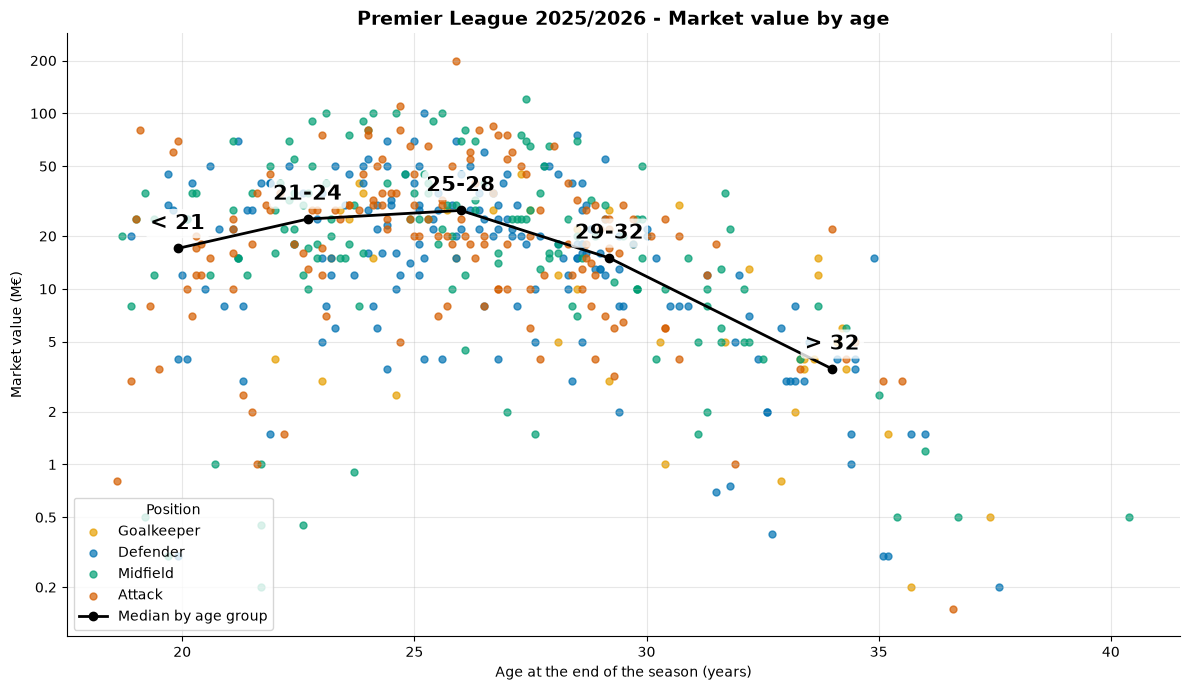

In [4]:
positions = ["Goalkeeper", "Defender", "Midfield", "Attack"]
# To make the scatter plot more understandable (because of the log)
VALUE_TICKS = [0.2, 0.5, 1, 2, 5, 10, 20, 50, 100, 200]
colors = {"Goalkeeper": "#E69F00", "Defender": "#0072B2", "Midfield": "#009E73", "Attack": "#D55E00"}

age_groups = pd.cut(pl_players_2025_26["age"], bins=[0, 21, 24, 28, 32, 50], labels=["< 21", "21-24", "25-28", "29-32", "> 32"])
median_by_age_group = pl_players_2025_26.groupby(age_groups, observed=True).agg(
    age=("age", "median"), value_end_eur=("value_end_eur", "median")
)

fig, ax = plt.subplots(figsize=(12, 7))
for pos in positions:
    p = pl_players_2025_26[pl_players_2025_26["position"] == pos]
    ax.scatter(p["age"], p["value_end_eur"] / 1e6, color=colors[pos], s=25, alpha=0.7, label=pos)

ax.plot(median_by_age_group["age"], median_by_age_group["value_end_eur"] / 1e6, color="black", linewidth=2, marker="o", label="Median by age group")
for group, row in median_by_age_group.iterrows():
    ax.annotate(group, (row["age"], row["value_end_eur"] / 1e6), textcoords="offset points", xytext=(0, 14), ha="center", fontsize=15, fontweight="bold", color="black",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.8))

ax.set_xlabel("Age at the end of the season (years)")
ax.set_ylabel("Market value (M€)")
ax.set_title("Premier League 2025/2026 - Market value by age", fontsize=14, fontweight="bold")
ax.legend(loc="lower left", title="Position")
ax.set_yscale("log")
ax.set_yticks(VALUE_TICKS, [f"{t:g}" for t in VALUE_TICKS])
ax.minorticks_off()
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(reports_figures / "age_vs_value.png", dpi=150)
plt.show()

In [5]:
pl_players_2025_26.groupby(age_groups, observed=True).agg(
    players=("player_id", "count"),
    median_value_m_eur=("value_end_eur", lambda x: round(x.median() / 1e6, 1)),
)

,players,median_value_m_eur
age,,
< 21,43,17.0
21-24,113,25.0
25-28,179,28.0
29-32,124,15.0
> 32,57,3.5


The market value peaks between 25-28 years old : 28 M€ median, then drops quickly for 29-32 years old players : 15 M€ and only 3.5 M€ after 32.

Market value by seasons of contract left. The players without a contract end date are at 0 (contract over, see the data dictionary).

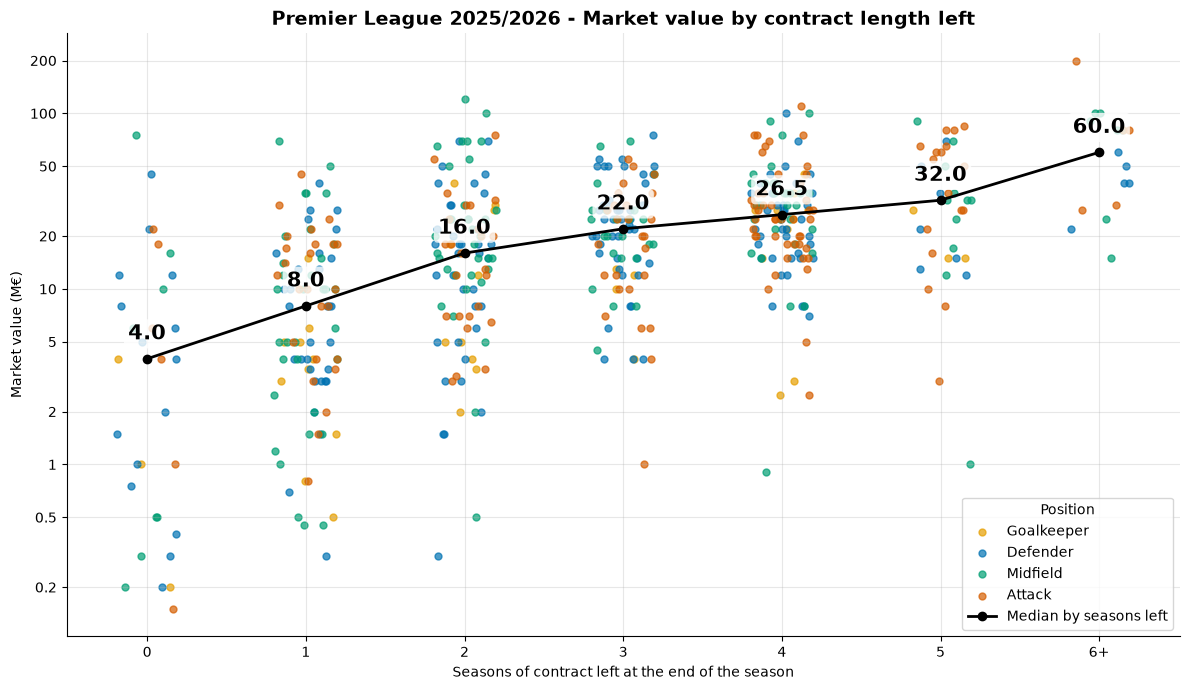

In [6]:
# The contracts end in June, so the years left are almost always x.1: round them to full seasons left.
seasons_left = pl_players_2025_26["contract_years_left"].round().astype(int).clip(upper=6)
seasons_left_labels = {n: "6+" if n == 6 else str(n) for n in range(7)}
median_by_seasons_left = pl_players_2025_26.groupby(seasons_left)["value_end_eur"].median()

# Small horizontal shift of the points, so the players with the same contract length do not hide each other.
jitter = np.random.default_rng(0).uniform(-0.2, 0.2, len(pl_players_2025_26))

fig, ax = plt.subplots(figsize=(12, 7))
for pos in positions:
    is_pos = (pl_players_2025_26["position"] == pos).to_numpy()
    p = pl_players_2025_26[is_pos]
    ax.scatter(seasons_left[is_pos] + jitter[is_pos], p["value_end_eur"] / 1e6, color=colors[pos], s=25, alpha=0.7, label=pos)

ax.plot(median_by_seasons_left.index, median_by_seasons_left / 1e6, color="black", linewidth=2, marker="o", label="Median by seasons left")
for n, value in median_by_seasons_left.items():
    ax.annotate(f"{value / 1e6:.1f}", (n, value / 1e6), textcoords="offset points", xytext=(0, 14), ha="center", fontsize=15, fontweight="bold", color="black",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.8))

ax.set_xticks(list(seasons_left_labels), list(seasons_left_labels.values()))
ax.set_xlabel("Seasons of contract left at the end of the season")
ax.set_ylabel("Market value (M€)")
ax.set_title("Premier League 2025/2026 - Market value by contract length left", fontsize=14, fontweight="bold")
ax.legend(loc="lower right", title="Position")
ax.set_yscale("log")
ax.set_yticks(VALUE_TICKS, [f"{t:g}" for t in VALUE_TICKS])
ax.minorticks_off()
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(reports_figures / "contract_vs_value.png", dpi=150)
plt.show()

In [7]:
pl_players_2025_26.groupby(seasons_left.map(seasons_left_labels).rename("seasons_left"), sort=False).agg(
    players=("player_id", "count"),
    median_value_m_eur=("value_end_eur", lambda x: round(x.median() / 1e6, 1)),
).sort_index()

,players,median_value_m_eur
seasons_left,,
0,32,4.0
1,99,8.0
2,106,16.0
3,98,22.0
4,126,26.5
5,38,32.0
6+,17,60.0


The longer the contract left, the higher the market value: from 4 M€ median for a contract over to 32 M€ for 5 seasons left. The best players also tend to get the longest contracts.

Market value by goals scored (goalkeepers excluded).

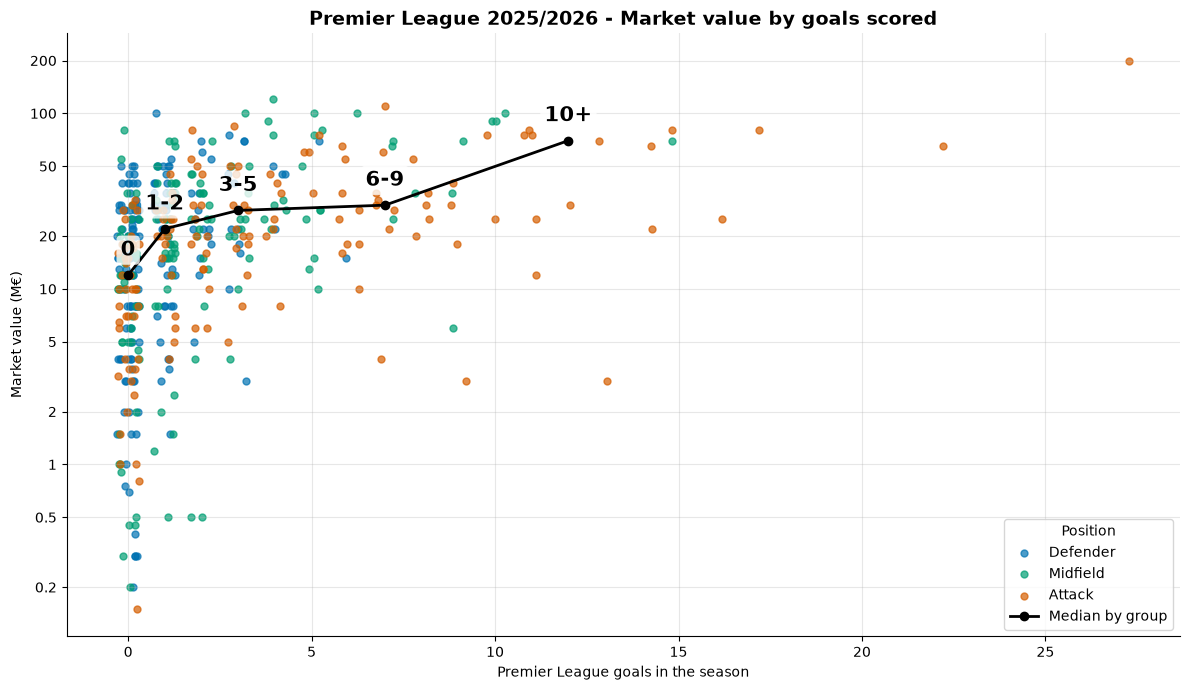

In [8]:
outfield_players = pl_players_2025_26[pl_players_2025_26["position"] != "Goalkeeper"]

goal_groups = pd.cut(outfield_players["goals"], bins=[-1, 0, 2, 5, 9, 40], labels=["0", "1-2", "3-5", "6-9", "10+"])
median_by_goal_groups = outfield_players.groupby(goal_groups, observed=True).agg(
    goals=("goals", "median"), value_end_eur=("value_end_eur", "median")
)

# Small horizontal shift of the points, so the players with the same number of goals do not hide each other.
jitter = np.random.default_rng(0).uniform(-0.3, 0.3, len(outfield_players))

fig, ax = plt.subplots(figsize=(12, 7))
for pos in positions[1:]:
    is_pos = (outfield_players["position"] == pos).to_numpy()
    p = outfield_players[is_pos]
    ax.scatter(p["goals"] + jitter[is_pos], p["value_end_eur"] / 1e6, color=colors[pos], s=25, alpha=0.7, label=pos)

ax.plot(median_by_goal_groups["goals"], median_by_goal_groups["value_end_eur"] / 1e6, color="black", linewidth=2, marker="o", label="Median by group")
for group, row in median_by_goal_groups.iterrows():
    ax.annotate(group, (row["goals"], row["value_end_eur"] / 1e6), textcoords="offset points", xytext=(0, 14), ha="center", fontsize=15, fontweight="bold", color="black",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.8))

ax.set_xlabel("Premier League goals in the season")
ax.set_ylabel("Market value (M€)")
ax.set_title("Premier League 2025/2026 - Market value by goals scored", fontsize=14, fontweight="bold")
ax.legend(loc="lower right", title="Position")
ax.set_yscale("log")
ax.set_yticks(VALUE_TICKS, [f"{t:g}" for t in VALUE_TICKS])
ax.minorticks_off()
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(reports_figures / "goals_vs_value.png", dpi=150)
plt.show()

In [9]:
outfield_players.groupby(goal_groups, observed=True).agg(
    players=("player_id", "count"),
    median_value_m_eur=("value_end_eur", lambda x: round(x.median() / 1e6, 1)),
)

,players,median_value_m_eur
goals,,
0,199,12.0
1-2,149,22.0
3-5,72,28.0
6-9,35,30.0
10+,21,70.0


The more goals a player scores, the more valuable he is on the market.

Market value by assists (goalkeepers excluded).

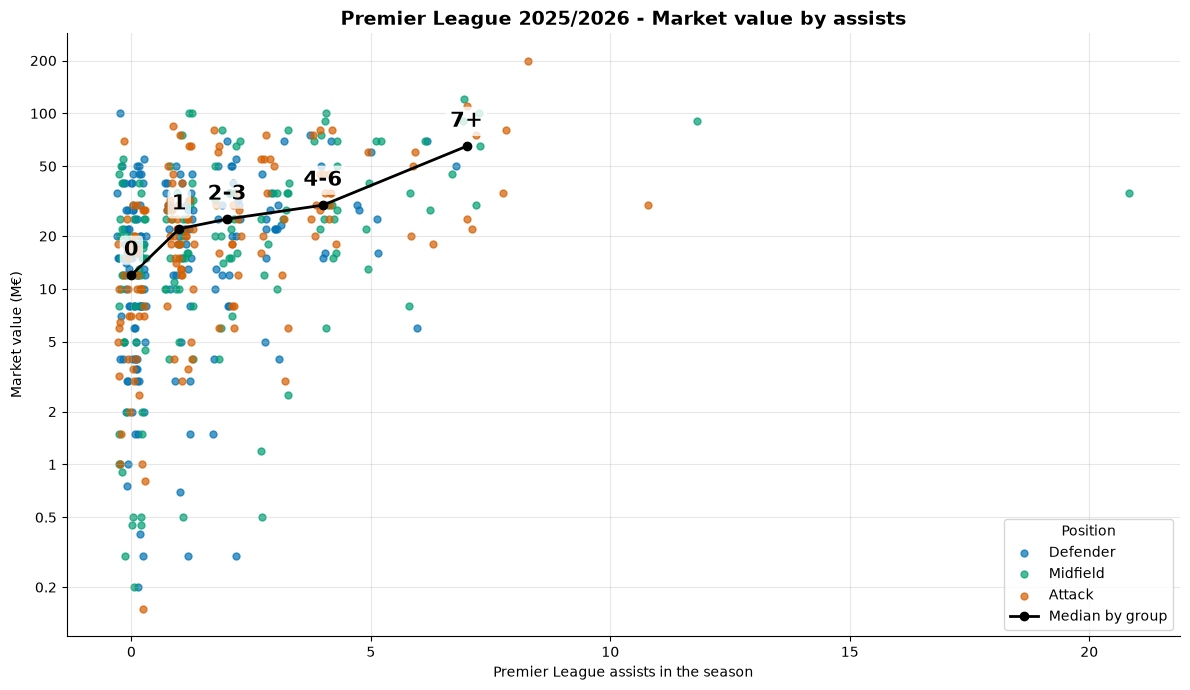

In [10]:
assist_groups = pd.cut(outfield_players["assists"], bins=[-1, 0, 1, 3, 6, 40], labels=["0", "1", "2-3", "4-6", "7+"])
median_by_assist_groups = outfield_players.groupby(assist_groups, observed=True).agg(
    assists=("assists", "median"), value_end_eur=("value_end_eur", "median")
)

# Small horizontal shift of the points, so the players with the same number of assists do not hide each other.
jitter = np.random.default_rng(0).uniform(-0.3, 0.3, len(outfield_players))

fig, ax = plt.subplots(figsize=(12, 7))
for pos in positions[1:]:
    is_pos = (outfield_players["position"] == pos).to_numpy()
    p = outfield_players[is_pos]
    ax.scatter(p["assists"] + jitter[is_pos], p["value_end_eur"] / 1e6, color=colors[pos], s=25, alpha=0.7, label=pos)

ax.plot(median_by_assist_groups["assists"], median_by_assist_groups["value_end_eur"] / 1e6, color="black", linewidth=2, marker="o", label="Median by group")
for group, row in median_by_assist_groups.iterrows():
    ax.annotate(group, (row["assists"], row["value_end_eur"] / 1e6), textcoords="offset points", xytext=(0, 14), ha="center", fontsize=15, fontweight="bold", color="black",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.8))

ax.set_xlabel("Premier League assists in the season")
ax.set_ylabel("Market value (M€)")
ax.set_title("Premier League 2025/2026 - Market value by assists", fontsize=14, fontweight="bold")
ax.legend(loc="lower right", title="Position")
ax.set_yscale("log")
ax.set_yticks(VALUE_TICKS, [f"{t:g}" for t in VALUE_TICKS])
ax.minorticks_off()
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(reports_figures / "assists_vs_value.png", dpi=150)
plt.show()

In [11]:
outfield_players.groupby(assist_groups, observed=True).agg(
    players=("player_id", "count"),
    median_value_m_eur=("value_end_eur", lambda x: round(x.median() / 1e6, 1)),
)

,players,median_value_m_eur
assists,,
0,188,12.0
1,111,22.0
2-3,102,25.0
4-6,58,30.0
7+,17,65.0


Logically, the more assists a player makes, the higher the market value. But as we saw earlier, it’s not a formality, as in the case of Bruno Fernandes (the green dot farthest to the right).

In [12]:
value_fernandes = pl_players_2025_26.loc[
    pl_players_2025_26["name"] == "Bruno Fernandes",
    "value_end_eur"
].iloc[0]

value_cherki = pl_players_2025_26.loc[
    pl_players_2025_26["name"] == "Rayan Cherki",
    "value_end_eur"
].iloc[0]

print(f"Bruno Fernandes market value at the end of the season (top 1 assists in the league) : {value_fernandes/1e6}M€")
print(f"Rayan Cherki market value at the end of the season (top 2 assists in the league) : {value_cherki/1e6}M€")

Bruno Fernandes market value at the end of the season (top 1 assists in the league) : 35.0M€
Rayan Cherki market value at the end of the season (top 2 assists in the league) : 90.0M€


Market value by appearances.

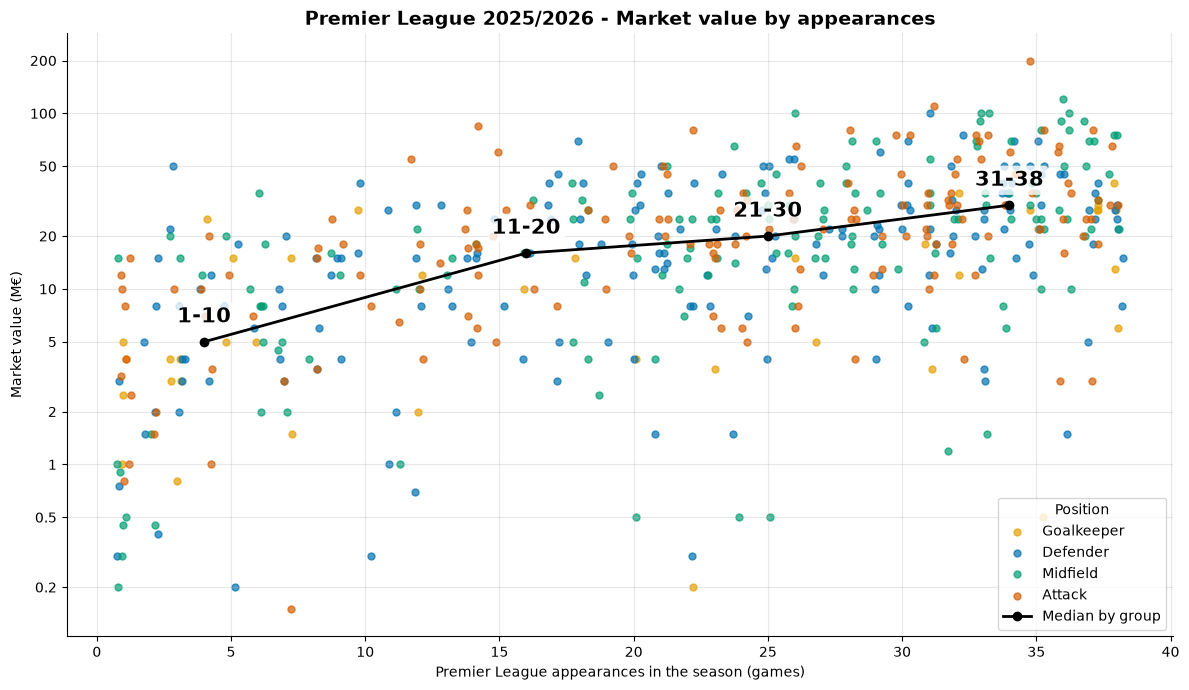

In [13]:
appearances_groups = pd.cut(pl_players_2025_26["appearances"], bins=[0, 10, 20, 30, 38], labels=["1-10", "11-20", "21-30", "31-38"])
median_by_appearances_groups = pl_players_2025_26.groupby(appearances_groups, observed=True).agg(
    appearances=("appearances", "median"), value_end_eur=("value_end_eur", "median")
)

# Small horizontal shift of the points, so the players with the same number of appearances do not hide each other.
jitter = np.random.default_rng(0).uniform(-0.3, 0.3, len(pl_players_2025_26))

fig, ax = plt.subplots(figsize=(12, 7))
for pos in positions:
    is_pos = (pl_players_2025_26["position"] == pos).to_numpy()
    p = pl_players_2025_26[is_pos]
    ax.scatter(p["appearances"] + jitter[is_pos], p["value_end_eur"] / 1e6, color=colors[pos], s=25, alpha=0.7, label=pos)

ax.plot(median_by_appearances_groups["appearances"], median_by_appearances_groups["value_end_eur"] / 1e6, color="black", linewidth=2, marker="o", label="Median by group")
for group, row in median_by_appearances_groups.iterrows():
    ax.annotate(group, (row["appearances"], row["value_end_eur"] / 1e6), textcoords="offset points", xytext=(0, 14), ha="center", fontsize=15, fontweight="bold", color="black",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.8))

ax.set_xlabel("Premier League appearances in the season (games)")
ax.set_ylabel("Market value (M€)")
ax.set_title("Premier League 2025/2026 - Market value by appearances", fontsize=14, fontweight="bold")
ax.legend(loc="lower right", title="Position")
ax.set_yscale("log")
ax.set_yticks(VALUE_TICKS, [f"{t:g}" for t in VALUE_TICKS])
ax.minorticks_off()
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(reports_figures / "appearances_vs_value.png", dpi=150)
plt.show()

In [14]:
pl_players_2025_26.groupby(appearances_groups, observed=True).agg(
    players=("player_id", "count"),
    median_value_m_eur=("value_end_eur", lambda x: round(x.median() / 1e6, 1)),
)

,players,median_value_m_eur
appearances,,
1-10,109,5.0
11-20,92,16.0
21-30,150,20.0
31-38,165,30.0


Starters are worth much more : 30M€ median with 31-38 games, against only 5M€ for those with 10 games or less.

Market value by minutes played.

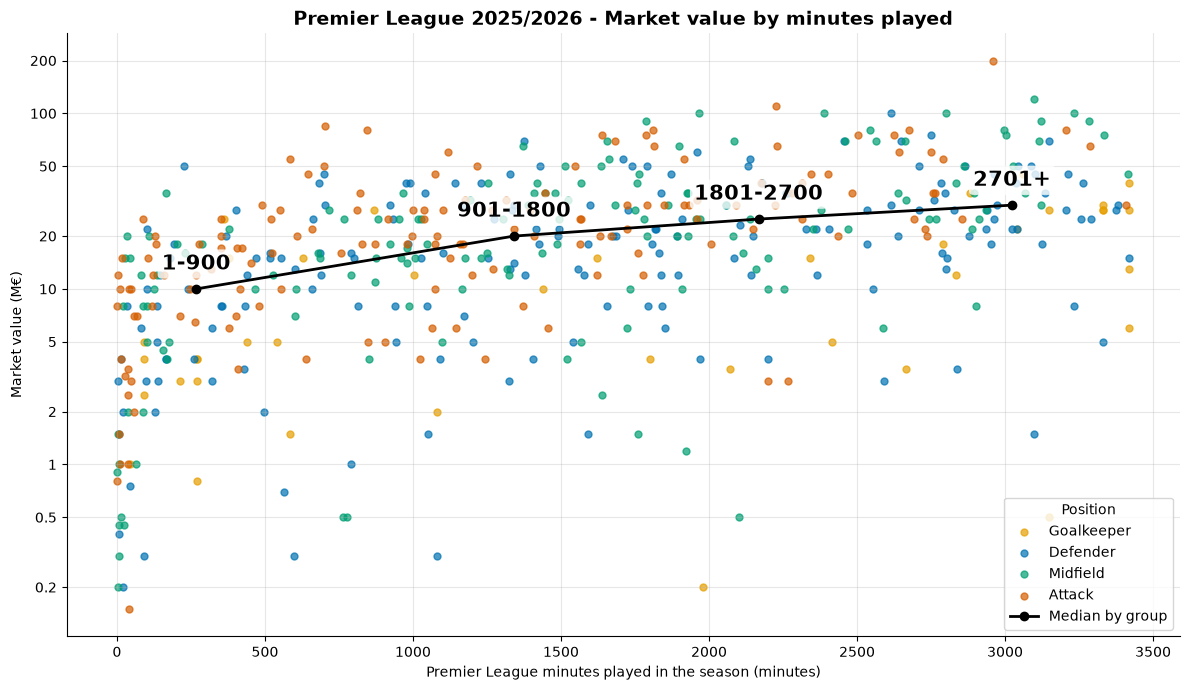

In [15]:
minutes_groups = pd.cut(pl_players_2025_26["minutes_played"], bins=[0, 900, 1800, 2700, 3420], labels=["1-900", "901-1800", "1801-2700", "2701+"])
median_by_minutes_groups = pl_players_2025_26.groupby(minutes_groups, observed=True).agg(
    minutes_played=("minutes_played", "median"), value_end_eur=("value_end_eur", "median")
)

jitter = np.zeros(len(pl_players_2025_26))

fig, ax = plt.subplots(figsize=(12, 7))
for pos in positions:
    is_pos = (pl_players_2025_26["position"] == pos).to_numpy()
    p = pl_players_2025_26[is_pos]
    ax.scatter(p["minutes_played"] + jitter[is_pos], p["value_end_eur"] / 1e6, color=colors[pos], s=25, alpha=0.7, label=pos)

ax.plot(median_by_minutes_groups["minutes_played"], median_by_minutes_groups["value_end_eur"] / 1e6, color="black", linewidth=2, marker="o", label="Median by group")
for group, row in median_by_minutes_groups.iterrows():
    ax.annotate(group, (row["minutes_played"], row["value_end_eur"] / 1e6), textcoords="offset points", xytext=(0, 14), ha="center", fontsize=15, fontweight="bold", color="black",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.8))

ax.set_xlabel("Premier League minutes played in the season (minutes)")
ax.set_ylabel("Market value (M€)")
ax.set_title("Premier League 2025/2026 - Market value by minutes played", fontsize=14, fontweight="bold")
ax.legend(loc="lower right", title="Position")
ax.set_yscale("log")
ax.set_yticks(VALUE_TICKS, [f"{t:g}" for t in VALUE_TICKS])
ax.minorticks_off()
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(reports_figures / "minutes_vs_value.png", dpi=150)
plt.show()

In [16]:
pl_players_2025_26.groupby(minutes_groups, observed=True).agg(
    players=("player_id", "count"),
    median_value_m_eur=("value_end_eur", lambda x: round(x.median() / 1e6, 1)),
)

,players,median_value_m_eur
minutes_played,,
1-900,176,10.0
901-1800,150,20.0
1801-2700,104,25.0
2701+,86,30.0


The more a player plays, the more important he is, and the higher his market value. 

Market value by position

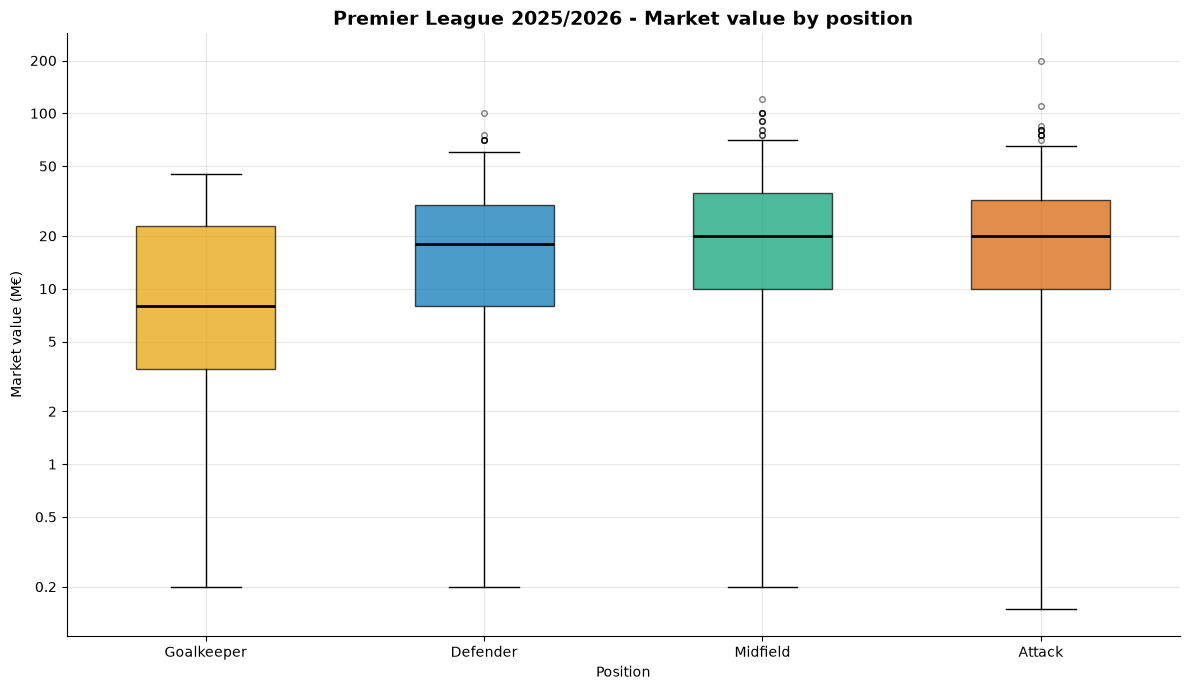

In [17]:
fig, ax = plt.subplots(figsize=(12, 7))
boxes = ax.boxplot(
    [pl_players_2025_26.loc[pl_players_2025_26["position"] == pos, "value_end_eur"] / 1e6 for pos in positions],
    tick_labels=positions, patch_artist=True, widths=0.5,
    medianprops=dict(color="black", linewidth=2), flierprops=dict(marker="o", markersize=4, alpha=0.5),
)
for box, pos in zip(boxes["boxes"], positions):
    box.set_facecolor(colors[pos])
    box.set_alpha(0.7)

ax.set_xlabel("Position")
ax.set_ylabel("Market value (M€)")
ax.set_title("Premier League 2025/2026 - Market value by position", fontsize=14, fontweight="bold")
ax.set_yscale("log")
ax.set_yticks(VALUE_TICKS, [f"{t:g}" for t in VALUE_TICKS])
ax.minorticks_off()
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(reports_figures / "position_vs_value.png", dpi=150)
plt.show()

In [18]:
pl_players_2025_26.groupby("position")["value_end_eur"].agg(
    players="count",
    median_value_m_eur=lambda x: round(x.median() / 1e6, 1),
    box_low_m_eur=lambda x: round(x.quantile(0.25) / 1e6, 1),
    box_high_m_eur=lambda x: round(x.quantile(0.75) / 1e6, 1),
).reindex(positions)

,players,median_value_m_eur,box_low_m_eur,box_high_m_eur
position,,,,
Goalkeeper,40,8.0,3.5,22.8
Defender,179,18.0,8.0,30.0
Midfield,148,20.0,10.0,35.0
Attack,149,20.0,10.0,32.0


In [19]:
value_raya = pl_players_2025_26.loc[
    pl_players_2025_26["name"] == "David Raya",
    "value_end_eur"
].iloc[0]

value_haaland = pl_players_2025_26.loc[
    pl_players_2025_26["name"] == "Erling Haaland",
    "value_end_eur"
].iloc[0]

print(f"The value of the best goalkeeper of the season (David Raya) : {value_raya/1e6}M€")
print(f"The value of the best goalscorer of the season (Erling Haaland) : {value_haaland/1e6}M€")

The value of the best goalkeeper of the season (David Raya) : 30.0M€
The value of the best goalscorer of the season (Erling Haaland) : 200.0M€


The median value is close for the outfield positions (18 to 20 M€), but goalkeepers are worth much less (8 M€): the position alone does not make a typical outfield player more or less valuable. What changes is the range: every position mixes cheap and expensive players, and the most expensive ones are attackers and midfielders (up to 200 M€ for Haaland).

The greater the range, the less the position tells about a player’s value. For a goalkeeper, you can expect a lower value. For an outfield player, it all depends on his profile and his season.

Market value by club: median value of the players of each club.

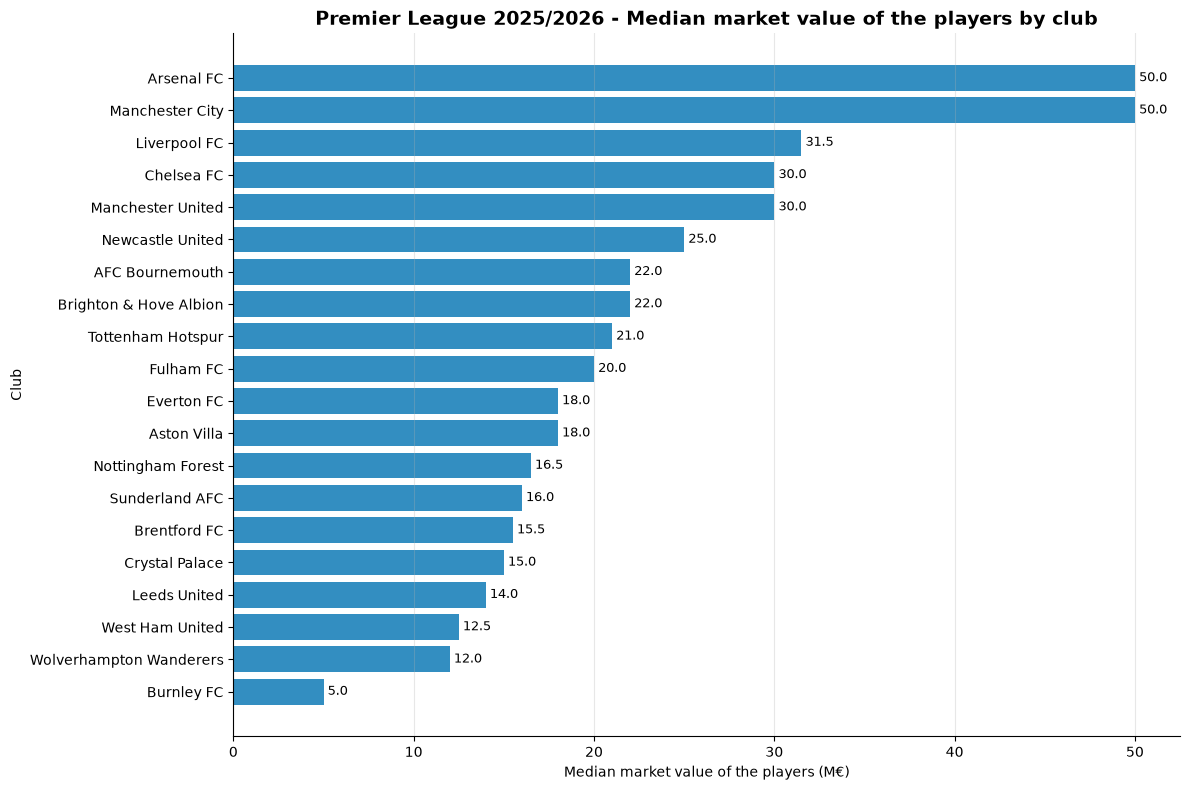

In [20]:
median_by_club = pl_players_2025_26.groupby("club")["value_end_eur"].median().sort_values() / 1e6

fig, ax = plt.subplots(figsize=(12, 8))
bars = ax.barh(median_by_club.index, median_by_club, color="#0072B2", alpha=0.8)
ax.bar_label(bars, labels=[f"{v:.1f}" for v in median_by_club], padding=3, fontsize=9)

ax.set_xlabel("Median market value of the players (M€)")
ax.set_ylabel("Club")
ax.set_title("Premier League 2025/2026 - Median market value of the players by club", fontsize=14, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
fig.savefig(reports_figures / "club_vs_value.png", dpi=150)
plt.show()

The club makes a big difference : the median player of Arsenal or Manchester City is worth 50 M€, ten times more than at Burnley (5 M€).

Market value by international caps.

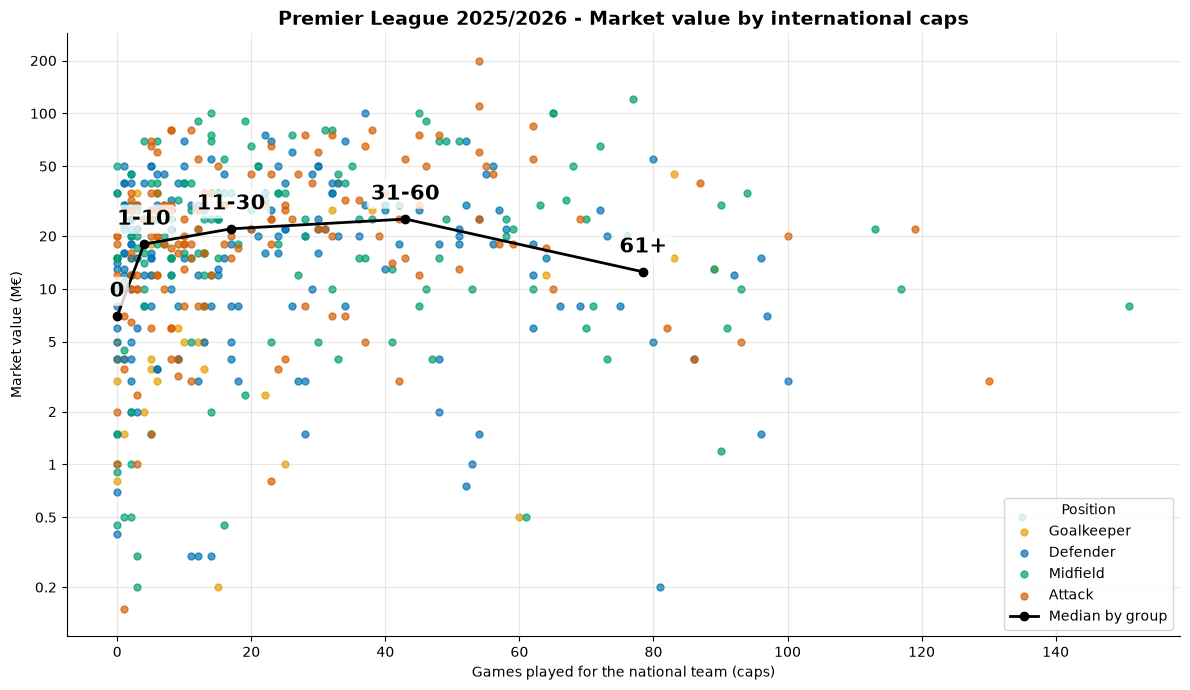

In [21]:
caps_groups = pd.cut(pl_players_2025_26["international_caps"], bins=[-1, 0, 10, 30, 60, 200], labels=["0", "1-10", "11-30", "31-60", "61+"])
median_by_caps_groups = pl_players_2025_26.groupby(caps_groups, observed=True).agg(
    international_caps=("international_caps", "median"), value_end_eur=("value_end_eur", "median")
)

jitter = np.zeros(len(pl_players_2025_26))

fig, ax = plt.subplots(figsize=(12, 7))
for pos in positions:
    is_pos = (pl_players_2025_26["position"] == pos).to_numpy()
    p = pl_players_2025_26[is_pos]
    ax.scatter(p["international_caps"] + jitter[is_pos], p["value_end_eur"] / 1e6, color=colors[pos], s=25, alpha=0.7, label=pos)

ax.plot(median_by_caps_groups["international_caps"], median_by_caps_groups["value_end_eur"] / 1e6, color="black", linewidth=2, marker="o", label="Median by group")
for group, row in median_by_caps_groups.iterrows():
    ax.annotate(group, (row["international_caps"], row["value_end_eur"] / 1e6), textcoords="offset points", xytext=(0, 14), ha="center", fontsize=15, fontweight="bold", color="black",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.8))

ax.set_xlabel("Games played for the national team (caps)")
ax.set_ylabel("Market value (M€)")
ax.set_title("Premier League 2025/2026 - Market value by international caps", fontsize=14, fontweight="bold")
ax.legend(loc="lower right", title="Position")
ax.set_yscale("log")
ax.set_yticks(VALUE_TICKS, [f"{t:g}" for t in VALUE_TICKS])
ax.minorticks_off()
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(reports_figures / "caps_vs_value.png", dpi=150)
plt.show()

In [22]:
pl_players_2025_26.groupby(caps_groups, observed=True).agg(
    players=("player_id", "count"),
    median_value_m_eur=("value_end_eur", lambda x: round(x.median() / 1e6, 1)),
)

,players,median_value_m_eur
international_caps,,
0,36,7.0
1-10,182,18.0
11-30,143,22.0
31-60,97,25.0
61+,58,12.5


International players are worth more, up to 25 M€ for 31 to 60 caps. Above 60 caps the value drops (12.5 M€), because these players are older (31 years old median).

Correlation between each criterion and the market value

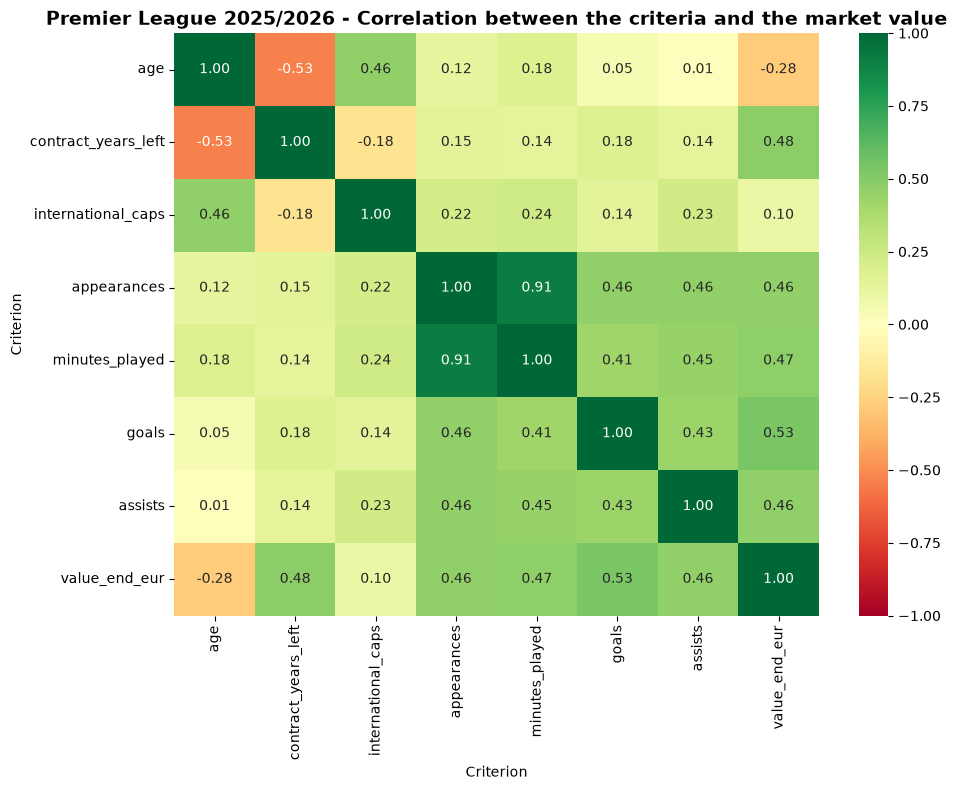

In [23]:
corr_columns = pl_players_2025_26[
    ["age", "contract_years_left", "international_caps", "appearances", "minutes_played",
     "goals", "assists", "value_end_eur"]
]

co_mtx = corr_columns.corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(co_mtx, cmap="RdYlGn", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", ax=ax)
ax.set_xlabel("Criterion")
ax.set_ylabel("Criterion")
ax.set_title("Premier League 2025/2026 - Correlation between the criteria and the market value", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [24]:
co_mtx["value_end_eur"].drop("value_end_eur").sort_values()

age                   -0.280307
international_caps     0.097469
assists                0.461055
appearances            0.464769
minutes_played         0.472278
contract_years_left    0.480688
goals                  0.533877
Name: value_end_eur, dtype: float64

All the criteria are linked to the market value in the expected direction. 

The strongest being the goals (0.53), the contract length (0.48) and the minutes played (0.47); age is the only negative link (−0.28). Appearances and minutes played are almost the same information (0.91), and age and contract length are linked (−0.53), so the model will have to separate their effects.

## Conclusion

- **Age**: the value peaks between 25 and 28 years old (28 M€ median), then drops quickly (3.5 M€ after 32).
- **Contract**: the longer the contract left, the higher the value, from 4 M€ for a contract over to 32 M€ for 5 seasons left.
- **Playing time**: starters are worth six times more than the players with 10 games or fewer (30 M€ against 5 M€). Appearances and minutes played give almost the same information, the minutes are more precise.
- **Goals and assists**: 10 goals or more go with a 70 M€ median value, against 12 M€ with no goal.
- **Club**: the median player of Arsenal or Manchester City is worth ten times more than at Burnley.
- **Position**: goalkeepers are worth much less (8 M€); the other positions are close.

No criterion explains the market value alone, and some of them are linked (age and contract length, appearances and minutes). The next step is a model that takes them all into account.